# CSC 425 Milestone 2: Data Preparation & Baseline

**Project:** Sentiment Analysis of IMDb Movie Reviews

**Focus question:** Can a TF-IDF model recognize how "not" changes the meaning of a review?

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from data_prep import prepare_data, load_challenge_set, load_split, clean_text
from baseline import run_experiments, predict_with_confidence, top_features

pd.set_option("display.max_colwidth", 120)

## 1. Load and explore the data

The full IMDb training split has 25,000 reviews. I draw a **balanced subset of 2,000 positive and 2,000 negative reviews**, then hold out **20% as a validation set**.

In [2]:
full_train = load_split("train")
print(f"Full training split: {len(full_train):,} reviews")
print(full_train["label"].value_counts().rename({0: "negative", 1: "positive"}))

Full training split: 25,000 reviews
label
negative    12500
positive    12500
Name: count, dtype: int64


In [3]:
train_df, val_df = prepare_data()
print(f"Train: {len(train_df)}   Validation: {len(val_df)}")
pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "validation": val_df["label"].value_counts(),
}).rename(index={0: "negative", 1: "positive"})

Train: 3200   Validation: 800


,train,validation
label,,
positive,1600,400
negative,1600,400


### Reading a few reviews from each class

In [4]:
for label, name in ((1, "POSITIVE"), (0, "NEGATIVE")):
    print(f"===== {name} =====")
    for text in train_df.loc[train_df["label"] == label, "text"].head(3):
        print("-", text[:400].replace("<br />", " "), "...\n")

===== POSITIVE =====
- The scenes are fast-paced. the characters are great. I love Anne-Marie Johnson's acting. I really like the ending.   However, I was disappointed that this movie didn't delve deeper into Achilles's and Athena's relationship. It only blossomed when they kissed each other. ...

- I have to say that this TV movie was the work that really showed how talented Melissa Joan Hart is. We are so used to, now, seeing her in a sitcom and I really hope that a TV station will show this TV movie again soon as it will show the Sabrina fans that MJH shines in a drama. Seen as we have watched her on Sabrina now for now 5 years and so to give the viewers a taste of her much unused talent w ...

- Actually, the answer only occupies a tiny portion of this excellent Imax movie that educates us on our delicate selves. C.G. and special cameras--assisted by Imax--incredibly display the inner (and outer) workings of an average human, be it adult men and women, boys and girls, or babies. Ne

### Preprocessing

Cleaning to remove the `<br />` HTML tags, lowercase, and collapse whitespace.

In [5]:
raw = train_df.loc[train_df["text"].str.contains("<br />"), "text"].iloc[0][:300]
print("BEFORE:", raw)
print()
print("AFTER: ", clean_text(raw))

BEFORE: The scenes are fast-paced. the characters are great. I love Anne-Marie Johnson's acting. I really like the ending. <br /><br />However, I was disappointed that this movie didn't delve deeper into Achilles's and Athena's relationship. It only blossomed when they kissed each other.

AFTER:  the scenes are fast-paced. the characters are great. i love anne-marie johnson's acting. i really like the ending. however, i was disappointed that this movie didn't delve deeper into achilles's and athena's relationship. it only blossomed when they kissed each other.


Words per review: mean 231, median 172, max 1501
Reviews containing the word 'not': 59%


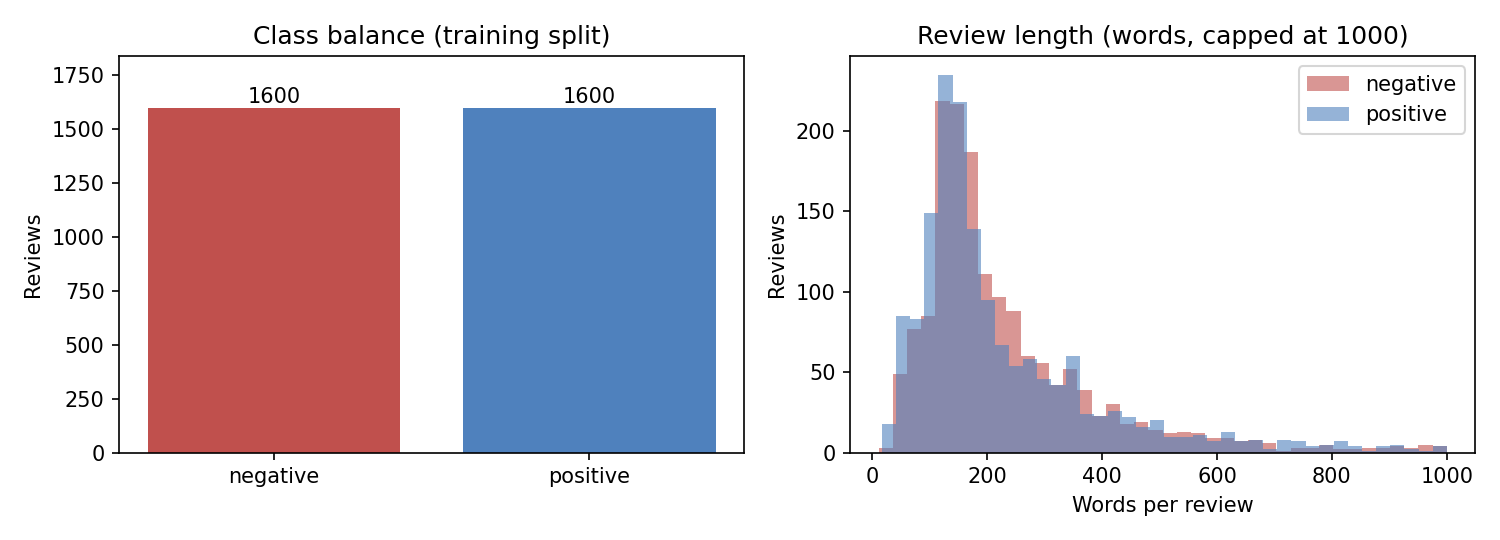

In [6]:
words = train_df["clean_text"].str.split().str.len()
print(f"Words per review: mean {words.mean():.0f}, median {words.median():.0f}, max {words.max()}")
print(f"Reviews containing the word 'not': {train_df['clean_text'].str.contains(r'\bnot\b').mean():.0%}")
display(Image("../results/figures/data_overview.png"))

## 2. Baseline models

In [7]:
results, models = run_experiments(train_df, val_df)
table = pd.DataFrame(results).round(3)
table

,model,version,n_features,fit_seconds,accuracy,precision,recall,f1
0,Majority class,-,0,0.00,0.500,0.000,0.000,0.000
1,LogReg,"A: words (1,1)",17291,0.51,0.856,0.864,0.845,0.855
2,LogReg,"B: words+pairs (1,2)",82919,1.59,0.882,0.892,0.870,0.881
3,NaiveBayes,"A: words (1,1)",17291,0.43,0.838,0.917,0.742,0.820
4,NaiveBayes,"B: words+pairs (1,2)",82919,1.42,0.862,0.934,0.780,0.850


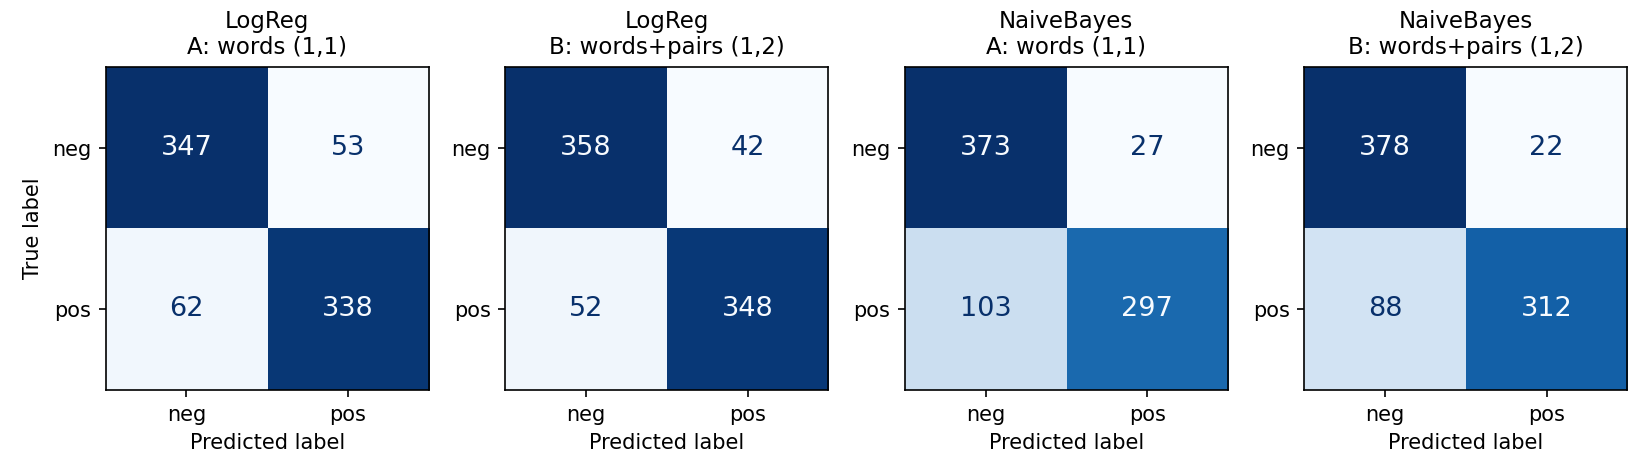

In [8]:
display(Image("../results/figures/confusion_matrices.png"))

## 3. Negation challenge set

Ten sentence pairs where adding "not" flips the opinion, written **before** any model was trained (see git history) and used only for analysis, never for training.

In [9]:
challenge = load_challenge_set()
LABELS = {0: "negative", 1: "positive"}
out = challenge[["pair_id", "text", "label"]].copy()
for (clf, version), pipe in models.items():
    preds, conf = predict_with_confidence(pipe, challenge["clean_text"])
    marks = ["" if p == t else " X" for p, t in zip(preds, challenge["label_id"])]
    out[f"{clf} {version[:1]}"] = [f"{LABELS[p]} ({c:.2f}){m}" for p, c, m in zip(preds, conf, marks)]
out

,pair_id,text,label,LogReg A,LogReg B,NaiveBayes A,NaiveBayes B
0,1,The movie was enjoyable.,positive,positive (0.55),negative (0.53) X,positive (0.54),negative (0.57) X
1,1,The movie was not enjoyable.,negative,negative (0.55),negative (0.60),positive (0.52) X,negative (0.60)
2,2,I would recommend this movie.,positive,positive (0.53),positive (0.55),positive (0.51),positive (0.58)
3,2,I would not recommend this movie.,negative,negative (0.58),negative (0.57),negative (0.51),negative (0.62)
4,3,The acting was good.,positive,negative (0.68) X,negative (0.64) X,negative (0.61) X,negative (0.68) X
5,3,The acting was not good.,negative,negative (0.77),negative (0.76),negative (0.62),negative (0.79)
6,4,This film is worth watching.,positive,positive (0.66),positive (0.65),negative (0.51) X,positive (0.59)
7,4,This film is not worth watching.,negative,positive (0.55) X,positive (0.50) X,negative (0.52),negative (0.61)
8,5,I liked the ending.,positive,positive (0.66),positive (0.62),positive (0.53),positive (0.54)
9,5,I did not like the ending.,negative,negative (0.64),negative (0.51),negative (0.60),negative (0.56)


In [10]:
pd.read_csv("../results/challenge_summary.csv")

,model,version,sentences_correct,base_correct,negated_correct,pairs_fully_correct
0,LogReg,"A: words (1,1)",13/20,8/10,5/10,3/10
1,LogReg,"B: words+pairs (1,2)",13/20,7/10,6/10,3/10
2,NaiveBayes,"A: words (1,1)",12/20,6/10,6/10,2/10
3,NaiveBayes,"B: words+pairs (1,2)",13/20,6/10,7/10,3/10


## 4. Why does negation fail? Looking inside the Logistic Regression model

A linear model gives each feature one weight; positive weights push toward "positive". Below are the learned weights of the words and word pairs that appear in the challenge sentences (Version B model), and how many training reviews contain each term.

In [11]:
pipe = models[("LogReg", "B: words+pairs (1,2)")]
vocab = pipe.named_steps["tfidf"].vocabulary_
coef = pipe.named_steps["clf"].coef_[0]
terms = ["not", "great", "not great", "good", "not good", "bad", "not bad",
         "boring", "not boring", "enjoyable", "not enjoyable", "funny", "not funny", "plot"]
pd.DataFrame([{
    "term": t,
    "weight": round(coef[vocab[t]], 3) if t in vocab else None,
    "training reviews containing it": int(train_df["clean_text"].str.contains(rf"\b{t}\b").sum()),
} for t in terms])

,term,weight,training reviews containing it
0,not,-1.115,1900
1,great,3.168,823
2,not great,0.172,9
3,good,0.010,1202
4,not good,-0.509,19
5,bad,-3.605,748
6,not bad,-0.054,16
7,boring,-1.709,188
8,not boring,NaN,0
9,enjoyable,0.263,112


In [12]:
pos, neg = top_features(models[("LogReg", "A: words (1,1)")], n=12)
pd.DataFrame({"most positive": [p[0] for p in pos], "w+": [p[1] for p in pos],
              "most negative": [n[0] for n in neg], "w-": [n[1] for n in neg]})

,most positive,w+,most negative,w-
0,great,4.169,bad,-4.274
1,excellent,2.316,worst,-3.345
2,best,2.205,awful,-2.618
3,very,2.186,worse,-2.458
4,perfect,2.006,waste,-2.442
5,love,1.974,boring,-2.362
6,job,1.922,nothing,-2.131
7,wonderful,1.896,terrible,-2.073
8,favorite,1.739,plot,-1.913
9,loved,1.655,or,-1.908


## 5. Demo: input -> model -> output

In [13]:
demo = [
    "The movie was good, but the ending ruined it.",
    "I expected to hate it, but I loved it.",
    "This film was not bad at all.",
    "One of the best films I have seen this year.",
]
for review in demo:
    row = [review]
    for version in ("A: words (1,1)", "B: words+pairs (1,2)"):
        (p,), (c,) = predict_with_confidence(models[("LogReg", version)], [clean_text(review)])
        row.append(f"{LABELS[p]} ({c:.2f})")
    print(f"{row[0]:50s} | A: {row[1]:17s} | B: {row[2]}")

The movie was good, but the ending ruined it.      | A: negative (0.55)   | B: negative (0.59)
I expected to hate it, but I loved it.             | A: positive (0.75)   | B: positive (0.65)
This film was not bad at all.                      | A: negative (0.95)   | B: negative (0.78)
One of the best films I have seen this year.       | A: positive (0.85)   | B: positive (0.80)
